# Seen from Roman, Seen from the Ground: Orbits of Distant Objects from the Galactic Bulge Survey

*Matthew Payne*

From 2027, the Nancy Grace Roman Space Telescope will stare at a few small fields towards the centre of the Milky Way for about 70 days at a time, imaging each one every 12 minutes, to find planets by gravitational microlensing: the Galactic Bulge Time Domain Survey. The fields lie only 5 to 6.5 degrees from the ecliptic, so distant Solar System objects, trans-Neptunian objects (TNOs) in particular, will drift through them, measured thousands of times with milliarcsecond precision (Gould 2014; Holler et al. 2018).

Such data should give remarkably good orbits from only a part of a season. But an orbit is only useful if it predicts where the object will be, and Roman sits about 1.5 million km from the Earth, near the Sun-Earth L2 point. Predictions for observers on the ground, for example of stellar occultations, which need a TNO's position to tens of km, are then made from a different place from the observations. How does the uncertainty of an orbit determined from Roman spread out when seen from Roman, and when seen from the Earth? How does that change with the object's distance, with the length of the stretch of data used, and with time?

We will:

1. Look at Roman's orbit and the survey's geometry.
2. Simulate Roman's observations of synthetic objects at 15 to 80 au, with idealised, known uncertainties.
3. Measure how well their orbits, and in particular their semi-major axes, are determined from 1 to 10 weeks of data.
4. Look at the uncertainty in position from two vantage points, Roman and the Earth, and see why they differ.
5. Separate what matters for predicting occultations: where the shadow path falls (across the motion) and when (along it), from Roman and from the ground, through the season and into the next one.

This is the fourth notebook in a series on orbital uncertainty; see also [NEOCP tracklets](../neocp_uncertainty/neocp_uncertainty.ipynb), [impact probabilities](../impact_probability/impact_probability.ipynb) and [occultations](../occultations/occultations.ipynb). Following the approach of the occultation notebook, the observations here are entirely synthetic, so that the geometry is not confused by imperfect real data (and Roman's survey has not yet begun).

**Requirements:** as for the other notebooks in the series (`orbunc` with ASSIST and its ephemeris files); Roman's trajectory is fetched from JPL Horizons and cached in `data/`.

**Run time:** about two minutes.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
from astropy.time import Time

from orbunc import ephem, frames, spacecraft
import roman   # helper module in this folder

warnings.filterwarnings("ignore", module="erfa")
rng = np.random.default_rng(211)
KM, JD = frames.AU_KM, ephem.JD_REF
ephem.get_ephem()
TRAJ = spacecraft.Trajectory(*spacecraft.fetch_vectors("-211", "2026-12-01", "2028-10-01", "6 h", cache_dir="data"))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Roman and the bulge survey

The survey's design was set by the Roman Observations Time Allocation Committee (ROTAC 2025). The numbers we use, with their sources:

| | |
|---|---|
| Fields | five contiguous fields plus one at the Galactic Centre, each about 0.28 deg², around RA 267.5°, Dec −29° (ROTAC 2025, Appendix C.3, Table 9) |
| Ecliptic latitude | about −5° to −6.5° |
| Seasons | about 72 days around each equinox, set by the Sun-angle limits; provisionally 2027 Feb 13 – Apr 25 and 2027 Aug 14 – Oct 30 (STScI Roman documentation) |
| Cadence | each field every 12.1 minutes in the wide F146 filter, 66.9-s exposures (ROTAC 2025) |
| Astrometry | about 87 mas / (signal-to-noise ratio) per exposure, with a floor of about 1.1 mas (McKinnon & van der Marel 2026; WFIRST Astrometry Working Group 2019) |
| Orbit | around the Sun-Earth L2 point, about 1.5 million km from the Earth; trajectory from JPL Horizons (target −211), a prediction made before arrival at L2 |

Roman launched on 2026 August 30; its trajectory, and the survey schedule, will change in detail. Here is where Roman is relative to the Earth during 2027, in a frame that keeps the Sun in a fixed direction, with the direction to the bulge fields.

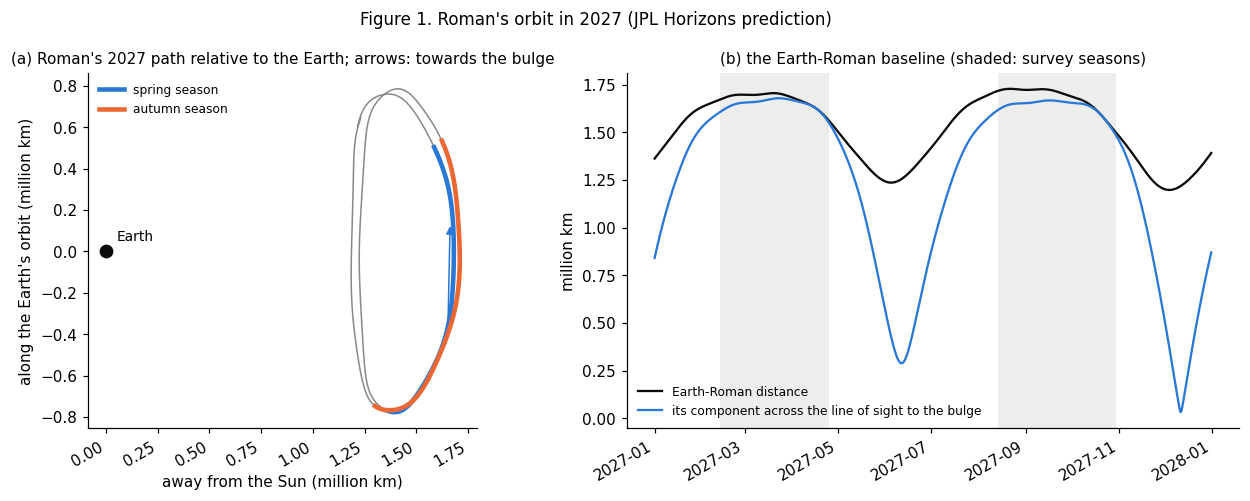

spring season: baseline across the line of sight 1.55 to 1.68 million km
autumn season: baseline across the line of sight 1.49 to 1.67 million km


In [2]:
t = Time("2027-01-01", scale="tdb").jd + np.arange(0, 365, 0.5) - JD
geo = TRAJ(t + JD)                                          # km, geocentric ICRF
sun = ephem.body_state("sun", t)[:, :3] - ephem.body_state("earth", t)[:, :3]
ev = ephem.body_state("earth", t)[:, 3:] - ephem.body_state("sun", t)[:, 3:]
xh = -sun / np.linalg.norm(sun, axis=1)[:, None]           # away from the Sun
zh = np.cross(xh, ev); zh /= np.linalg.norm(zh, axis=1)[:, None]
yh = np.cross(zh, xh)
X, Y, Z = (np.sum(geo * v, 1) / 1e6 for v in (xh, yh, zh))
u_field = frames.radec_to_unit(*np.radians(roman.FIELDS["3"]))
B_perp = np.linalg.norm(geo - np.outer(geo @ u_field, u_field), axis=1) / 1e6   # baseline across the line of sight

fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
ax = axs[0]
ax.plot(X, Y, color=roman.MUTED, lw=1)
for (a, b), c, lab in [(roman.SPRING_2027, roman.ROMAN_C, "spring season"), (roman.AUTUMN_2027, roman.COLOURS[1], "autumn season")]:
    k = (t + JD >= Time(a).jd) & (t + JD <= Time(b).jd)
    ax.plot(X[k], Y[k], color=c, lw=3, label=lab)
    m = np.where(k)[0][len(np.where(k)[0]) // 2]
    d = np.array([u_field @ xh[m], u_field @ yh[m]]); d /= np.linalg.norm(d)
    ax.annotate("", (X[m] + 0.5 * d[0], Y[m] + 0.5 * d[1]), (X[m], Y[m]), arrowprops=dict(arrowstyle="-|>", color=c))
ax.plot(0, 0, "o", color=roman.INK, ms=8)
ax.text(0.05, 0.05, "Earth", fontsize=9)
ax.annotate("to the Sun", (-0.4, 0), (0.2, 0.0), arrowprops=dict(arrowstyle="-|>", color="#eda100"), fontsize=8, va="center")
ax.set_aspect("equal")
ax.set_xlabel("away from the Sun (million km)")
ax.set_ylabel("along the Earth's orbit (million km)")
ax.legend(fontsize=8, frameon=False, loc="upper left")
ax.set_title("(a) Roman's 2027 path relative to the Earth; arrows: towards the bulge", fontsize=10)
ax = axs[1]
ax.plot(Time(t + JD, format="jd").datetime, np.linalg.norm(geo, axis=1) / 1e6, color=roman.INK, lw=1.5, label="Earth-Roman distance")
ax.plot(Time(t + JD, format="jd").datetime, B_perp, color=roman.ROMAN_C, lw=1.5, label="its component across the line of sight to the bulge")
for a, b in (roman.SPRING_2027, roman.AUTUMN_2027):
    ax.axvspan(Time(a).datetime, Time(b).datetime, color=roman.MUTED, alpha=0.15, lw=0)
ax.set_ylabel("million km")
ax.legend(fontsize=8, frameon=False)
fig.autofmt_xdate()
ax.set_title("(b) the Earth-Roman baseline (shaded: survey seasons)", fontsize=10)
fig.suptitle("Figure 1. Roman's orbit in 2027 (JPL Horizons prediction)", fontsize=11)
plt.tight_layout()
plt.show()
for (a, b), lab in [(roman.SPRING_2027, "spring"), (roman.AUTUMN_2027, "autumn")]:
    k = (t + JD >= Time(a).jd) & (t + JD <= Time(b).jd)
    print(f"{lab} season: baseline across the line of sight {B_perp[k].min():.2f} to {B_perp[k].max():.2f} million km")

The bulge is observed near quadrature, about 90° from the Sun, so the line of sight runs roughly perpendicular to the Sun-Earth line, and Roman's offset from the Earth, mostly away from the Sun, lies largely *across* it. That offset is a baseline of more than a million kilometres between the place where the observations are made and the place where many predictions will be used.

## 2. Synthetic distant objects and their observations

We place four synthetic objects on the line of sight from Roman to the centre of field 3 in the middle of the spring 2027 season (March 21), on near-circular orbits inclined by about 8°: a Centaur at 15 au, a plutino-like object at 39 au, a classical TNO at 44 au and a distant object at 80 au.

Roman measures each object every 12.1 minutes; we bin the exposures in groups of five, one point an hour. For the per-exposure precision we take a source of F146 = 24 AB, for which the formula above gives about 11 mas (S/N about 8; for an albedo of 0.1, a TNO roughly 100 km across at 40 au would be about this faint, while one of 300 km would be some 2.5 magnitudes brighter; Roman's single-exposure detection limit is near 25.4). The errors are independent and Gaussian, so the orbit fits' uncertainties are right by construction.

Centaur, 15 au        : distance from Roman  14.9 au
plutino, 39 au        : distance from Roman  39.4 au
classical TNO, 44 au  : distance from Roman  44.0 au
distant, 80 au        : distance from Roman  80.0 au
precision per exposure at F146 = 24.0: 11.5 mas; per hourly point 5.2 mas


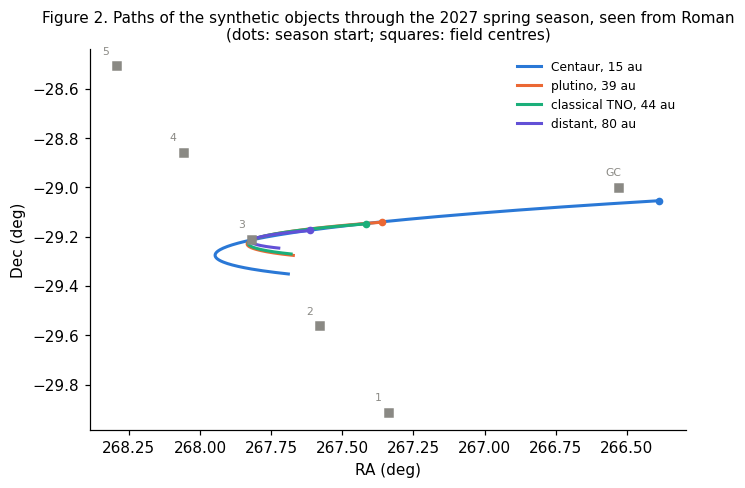

Centaur, 15 au        : apparent rate from 7.79 down to 0.635 arcsec/h, slowest on 2027-04-04 (its stationary point)


plutino, 39 au        : apparent rate from 2.72 down to 0.299 arcsec/h, slowest on 2027-03-29 (its stationary point)


classical TNO, 44 au  : apparent rate from 2.41 down to 0.272 arcsec/h, slowest on 2027-03-28 (its stationary point)
distant, 80 au        : apparent rate from 1.27 down to 0.160 arcsec/h, slowest on 2027-03-26 (its stationary point)


In [3]:
MAG = 24.0
SIG_EXP = roman.precision_mas(MAG)
T_MID = Time("2027-03-21", scale="tdb").jd - JD
OBJECTS = {"Centaur, 15 au": 15.0, "plutino, 39 au": 39.4, "classical TNO, 44 au": 44.0, "distant, 80 au": 80.0}
truth = {}
for name, r in OBJECTS.items():
    x, rho = roman.place(TRAJ, T_MID, *roman.FIELDS["3"], r, r, 8.0)
    truth[name] = x
    print(f"{name:22s}: distance from Roman {rho:5.1f} au")
print(f"precision per exposure at F146 = {MAG}: {SIG_EXP:.1f} mas; per hourly point {SIG_EXP / np.sqrt(5):.1f} mas")

fig, ax = plt.subplots(figsize=(7, 4.5))
season = Time(roman.SPRING_2027[0]).jd + np.arange(0, 71, 0.5)
ts = Time(season, format="jd", scale="utc").tdb.jd - JD
o = roman.observer(TRAJ, ts, "Roman")
for (name, x), c in zip(truth.items(), roman.COLOURS):
    P = ephem.propagate(x[None], T_MID, ts)[:, 0, :3] - o
    ra, dec = frames.unit_to_radec(P)
    ax.plot(np.degrees(ra), np.degrees(dec), color=c, lw=2, label=name)
    ax.plot(np.degrees(ra[0]), np.degrees(dec[0]), "o", color=c, ms=4)
for f, (ra_f, dec_f) in roman.FIELDS.items():
    ax.plot(ra_f, dec_f, "s", color=roman.MUTED, ms=5)
    ax.text(ra_f + 0.05, dec_f + 0.05, f, fontsize=7, color=roman.MUTED)
ax.invert_xaxis()
ax.set_xlabel("RA (deg)"); ax.set_ylabel("Dec (deg)")
ax.legend(fontsize=8, frameon=False)
ax.set_title("Figure 2. Paths of the synthetic objects through the 2027 spring season, seen from Roman\n(dots: season start; squares: field centres)", fontsize=10)
plt.show()
for name, x in truth.items():
    P = ephem.propagate(x[None], T_MID, ts)[:, 0, :3] - o
    u = P / np.linalg.norm(P, axis=1)[:, None]
    rate = np.degrees(np.arccos(np.clip(np.sum(u[1:] * u[:-1], 1), -1, 1))) * 3600 / 12   # arcsec per hour (0.5-d steps)
    k = np.argmin(rate)
    print(f"{name:22s}: apparent rate from {rate.max():.2f} down to {rate[k]:.3f} arcsec/h, slowest on "
          f"{Time(season[k], format='jd').iso[:10]} (its stationary point)")

Over a 70-day season a TNO moves less than a degree, so it can cross a field (about 0.8° by 0.4°) in a few weeks; the Centaur moves faster. The paths also turn round: the bulge is observed near quadrature, where distant objects reach their *stationary points*, when the observer's own motion around the Sun cancels their east-west motion and they turn round in right ascension; their apparent motion is then slowest (late March here, printed above). This will matter in Section 5. A TNO that passes through the survey will typically be measured over a part of a season, not all of it: the natural question is what a *partial* stare gives.

## 3. How well is the orbit determined from part of a season?

We fit each object's orbit to arcs of 1 to 10 weeks starting on the first day of the season, and measure the uncertainty of the semi-major axis, $\sigma_a/a$, from the fit's covariance (sampled, and converted to orbital elements).

Centaur, 15 au         sigma_a/a: 7 d 6.3e-03, 10 d 2.3e-03, 14 d 9.4e-04, 21 d 3.1e-04, 28 d 1.3e-04, 42 d 3.3e-05, 70 d 4.8e-06


plutino, 39 au         sigma_a/a: 7 d 3.9e-02, 10 d 1.5e-02, 14 d 3.2e-03, 21 d 7.1e-04, 28 d 4.1e-04, 42 d 1.1e-04, 70 d 1.7e-05


classical TNO, 44 au   sigma_a/a: 7 d 7.5e-01, 10 d 1.8e-02, 14 d 2.5e-03, 21 d 1.1e-03, 28 d 6.0e-04, 42 d 1.2e-04, 70 d 2.0e-05


distant, 80 au         sigma_a/a: 7 d 1.8e+01, 10 d 1.1e+00, 14 d 5.7e-02, 21 d 4.9e-03, 28 d 1.5e-03, 42 d 4.6e-04, 70 d 4.5e-05


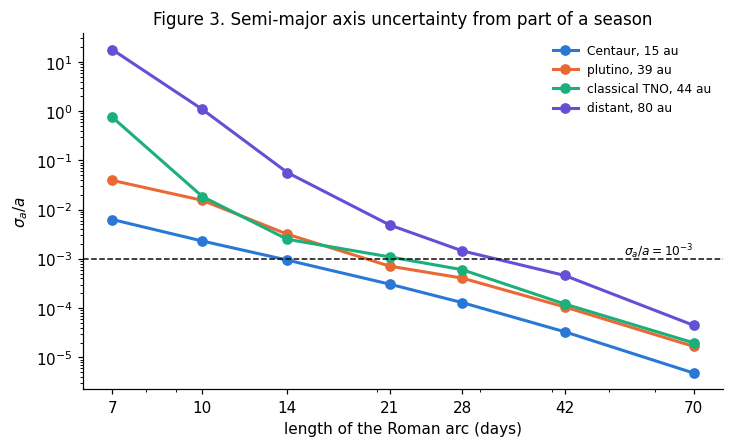

In [4]:
ARCS = [7, 10, 14, 21, 28, 42, 70]
fits, da = {}, {}
for name, x in truth.items():
    da[name] = []
    for arc in ARCS:
        O = roman.observe(TRAJ, x, T_MID, roman.SPRING_2027[0], arc, SIG_EXP, rng)
        f = roman.fit_from_truth(O, x, T_MID)
        S = rng.multivariate_normal(f.state, f.cov, 2000)
        el = frames.elements(frames.bary_eq_to_helio_ec(S, f.t))
        da[name].append(np.std(el["a"]) / np.mean(el["a"]))
        fits[(name, arc)] = (O, f, S)
    print(f"{name:22s} sigma_a/a: " + ", ".join(f"{arc} d {v:.1e}" for arc, v in zip(ARCS, da[name])))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for (name, v), c in zip(da.items(), roman.COLOURS):
    ax.plot(ARCS, v, "o-", color=c, lw=2, label=name)
ax.axhline(1e-3, color=roman.INK, ls="--", lw=1)
ax.text(70, 1.2e-3, r"$\sigma_a/a = 10^{-3}$", ha="right", fontsize=8)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xticks(ARCS); ax.set_xticklabels(ARCS); ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("length of the Roman arc (days)")
ax.set_ylabel(r"$\sigma_a / a$")
ax.legend(fontsize=8, frameon=False)
ax.set_title("Figure 3. Semi-major axis uncertainty from part of a season", fontsize=11)
plt.show()

The uncertainty falls steeply with the length of the arc, roughly as a high power of it: a longer arc both adds measurements and, more importantly, lets the curvature of the path, which is what reveals the distance and the orbit, grow. An uncertainty of $\sigma_a/a \approx 10^{-3}$ is reached with two to four weeks of data for a TNO with these measurement errors, and sooner for the nearer Centaur; the full season does far better. (For ground-based data, by contrast, it takes years of observations to reach this; Bernstein & Khushalani 2000 describe the short-arc degeneracies of TNO orbits.) Closer objects are better determined for the same arc, because their apparent path curves more.

## 4. The uncertainty from two vantage points

Take the plutino-like object after a 14-day arc. Its orbit predicts a position at any time, with an uncertainty that is a three-dimensional cloud. On the sky we describe it in two directions: *along-track*, along the object's apparent motion on the sky as seen by the observer, and *cross-track*, perpendicular to it. Roman's data measure directions from Roman very well, but the distance from Roman less well: so the cloud is long and thin, pointing along Roman's line of sight. Figure 4 shows it at the end of the arc, side on, and face on from Roman and from the Earth.

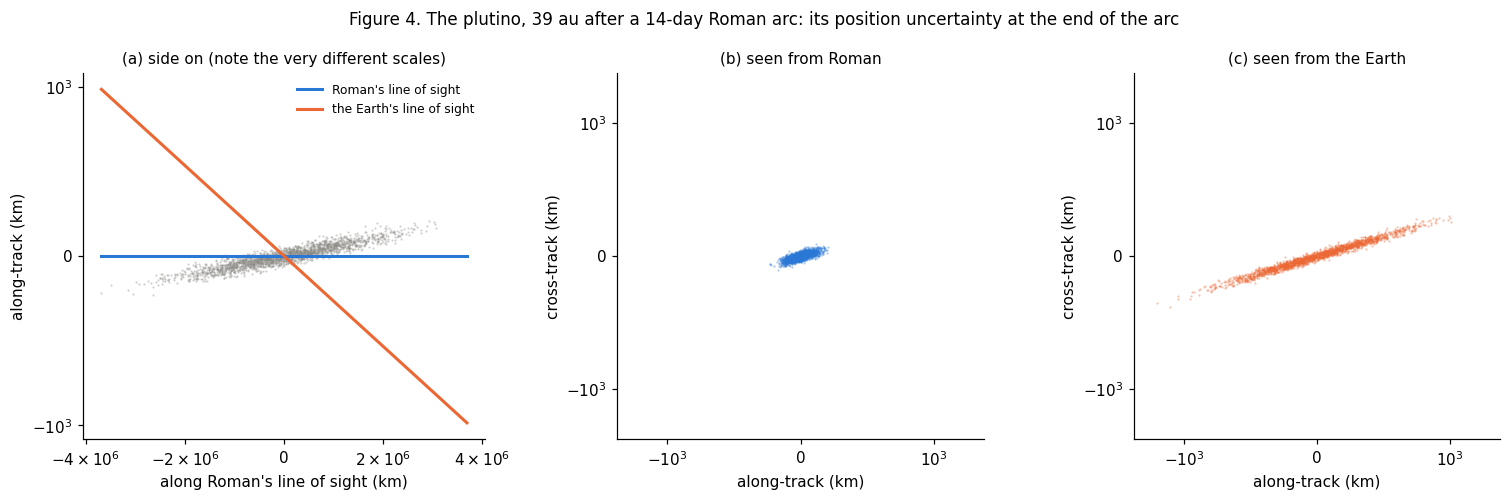

distance uncertainty along Roman's line of sight: 1,057,077 km (1.8e-04 of the distance)
baseline Earth-Roman across the line of sight: 1.66 million km; expected extra spread B x sigma_rho / rho = 294 km
seen from Roman: 1-sigma along the motion     66 km, across it    26 km
seen from Earth: 1-sigma along the motion    344 km, across it   105 km


In [5]:
NAME, ARC = "plutino, 39 au", 14
O, f, S = fits[(NAME, ARC)]
t_end = O.t[-1]
sp = roman.spread(S, f.t, f.state, t_end, TRAJ)
cR, cE = sp["Roman"]["cloud"], sp["Earth"]["cloud"]
fig, axs = plt.subplots(1, 3, figsize=(14, 4.6))
ax = axs[0]
ax.scatter(cR[:, 2], cR[:, 0], s=2, color=roman.MUTED, alpha=0.4, lw=0, rasterized=True)
L = np.abs(cR[:, 2]).max()
oR, oE = roman.observer(TRAJ, t_end, "Roman")[0], roman.observer(TRAJ, t_end, "Earth")[0]
base = (oR - oE) * KM
FR = roman.apparent_frame(ephem.propagate(f.state[None], f.t, [t_end])[0, 0], t_end, oR, roman.observer(TRAJ, t_end + 0.01, "Roman")[0])[0]
dist_km = sp["Roman"]["dist_au"] * KM
slope = (base @ FR[0]) / dist_km      # change of the Earth's sightline, along-track, per km along Roman's
xs = np.array([-L, L])
ax.plot(xs, 0 * xs, color=roman.ROMAN_C, lw=2, label="Roman's line of sight")
ax.plot(xs, slope * xs, color=roman.EARTH_C, lw=2, label="the Earth's line of sight")
ax.set_xlabel("along Roman's line of sight (km)")
ax.set_ylabel("along-track (km)")
ax.legend(fontsize=8, frameon=False)
ax.set_title("(a) side on (note the very different scales)", fontsize=10)
roman.sci_ticks(ax)
lim = 4 * max(sp["Earth"]["along"], sp["Earth"]["across"])
for ax, who, c in [(axs[1], "Roman", roman.ROMAN_C), (axs[2], "Earth", roman.EARTH_C)]:
    d = sp[who]["cloud"]
    ax.scatter(d[:, 0], d[:, 1], s=2, color=c, alpha=0.4, lw=0, rasterized=True)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.set_xlabel("along-track (km)")
    ax.set_ylabel("cross-track (km)")
    ax.set_title(f"(c) seen from the Earth" if who == "Earth" else "(b) seen from Roman", fontsize=10)
    roman.sci_ticks(ax)
fig.suptitle(f"Figure 4. The {NAME} after a {ARC}-day Roman arc: its position uncertainty at the end of the arc", fontsize=11)
plt.tight_layout()
plt.show()
B = np.linalg.norm(base - (base @ FR[2]) * FR[2])
print(f"distance uncertainty along Roman's line of sight: {sp['Roman']['los']:,.0f} km ({sp['Roman']['los'] / dist_km:.1e} of the distance)")
print(f"baseline Earth-Roman across the line of sight: {B / 1e6:.2f} million km; expected extra spread "
      f"B x sigma_rho / rho = {B * sp['Roman']['los'] / dist_km:,.0f} km")
for who in ("Roman", "Earth"):
    print(f"seen from {who:5s}: 1-sigma along the motion {sp[who]['along']:6.0f} km, across it {sp[who]['across']:5.0f} km")

Seen from Roman (b), the cloud is compact: Roman measured these directions directly. Seen from the Earth (c) it is several times longer. Nothing about the cloud has changed: the Earth simply looks at the long, thin cloud from a slightly different direction, and sees some of its length (a). The angle is tiny, the baseline divided by the distance, about $1.6\times10^6\,{\rm km}/5.9\times10^9\,{\rm km} \approx 3\times10^{-4}$ rad, but the cloud is more than a million km long, so the extra spread is about

$$\Delta \approx B_\perp \, \frac{\sigma_\rho}{\rho},$$

the baseline across the line of sight times the *fractional* uncertainty of the distance, here a few hundred km. It does not depend on the distance itself, only on how well it is known in proportion.

## 5. Predicting occultations, from Roman and from the ground

For a stellar occultation the two directions on the sky play different roles. The asteroid's shadow sweeps across the observer's plane along the direction of the apparent motion, so an error **along** the motion only shifts the *time* of the event (by the error divided by the shadow's speed); an error **across** the motion shifts the *path*, and decides whether a given observer sees the event at all. A TNO a few hundred km across can be observed only if the path is known to a fraction of its size.

Here is how both evolve over the 60 days after the end of 14- and 28-day arcs (beyond the end of the season, Roman can no longer observe the field, but predictions for the ground still matter), for observers at Roman and on the Earth (the Earth's centre; observers on its surface differ by at most its radius, negligible here). The table after the figure continues into the autumn season. Panel (a) shows the whole uncertainty, the major axis of the uncertainty ellipse on the sky, which does not depend on the direction of motion; (b) and (c) split it into its cross-track and along-track parts.

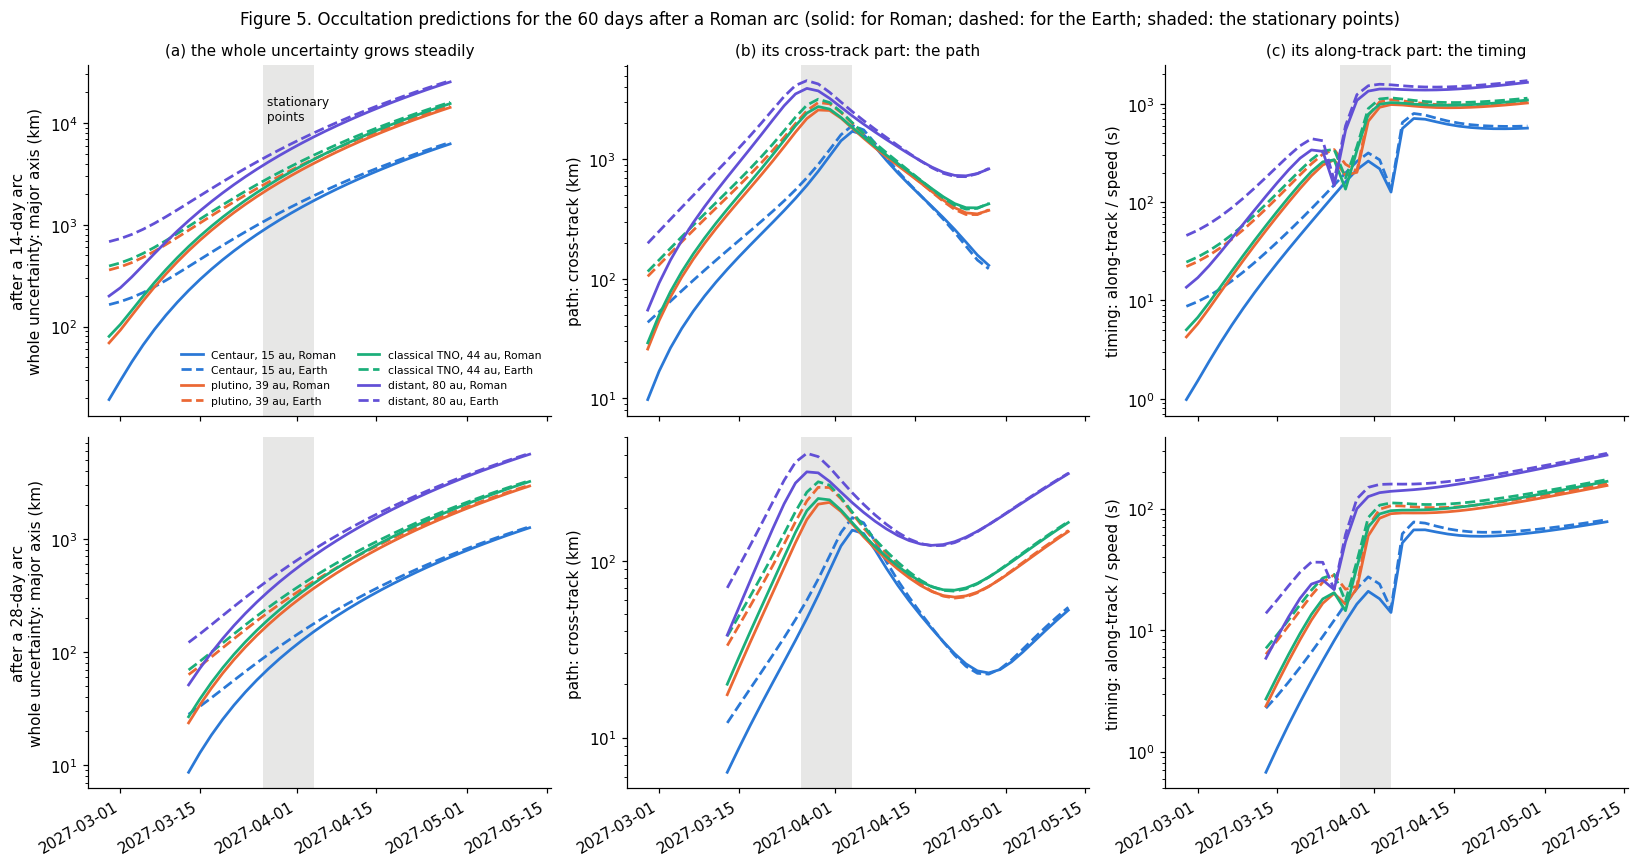

Centaur, 15 au         after the full 70-day arc, at the start of the autumn season: across 105 km, timing 33 s (for the Earth)


plutino, 39 au         after the full 70-day arc, at the start of the autumn season: across 186 km, timing 63 s (for the Earth)


classical TNO, 44 au   after the full 70-day arc, at the start of the autumn season: across 204 km, timing 69 s (for the Earth)


distant, 80 au         after the full 70-day arc, at the start of the autumn season: across 323 km, timing 110 s (for the Earth)

object                  arc             when   across (km): Roman / Earth   timing (s): Roman / Earth
Centaur, 15 au           14       end of arc           10 / 43                      1 / 9         
Centaur, 15 au           14             +7 d           46 / 88                      5 / 14        
Centaur, 15 au           14            +28 d          604 / 700                   161 / 198       
Centaur, 15 au           14    autumn season       22,206 / 21,837              6,431 / 6,436     
Centaur, 15 au           28       end of arc            6 / 12                      1 / 2         
Centaur, 15 au           28             +7 d           18 / 26                      3 / 6         
Centaur, 15 au           28            +28 d           91 / 99                     67 / 76        
Centaur, 15 au           28    autumn season        2,967 / 2,915          

In [6]:
LATER = [0, 3, 7, 14, 28, 56]
autumn = Time(roman.AUTUMN_2027[0], scale="utc").tdb.jd - JD
STATIONARY = (Time("2027-03-26").datetime, Time("2027-04-04").datetime)   # the objects' slowest motion (Section 2)
series = {}
for name in truth:
    for arc in (14, 28):
        O, f, S = fits[(name, arc)]
        tt = O.t[-1] + np.arange(0, 61, 2.0)
        series[(name, arc)] = (tt, roman.spread_series(S, f.t, f.state, tt, TRAJ))

fig, axs = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
for row, arc in enumerate((14, 28)):
    for (name, x), c in zip(truth.items(), roman.COLOURS):
        tt, sp = series[(name, arc)]
        dates = Time(tt + JD, format="jd", scale="tdb").datetime
        for who, ls in (("Roman", "-"), ("Earth", "--")):
            r = sp[who]
            lab = f"{name}, {who}" if row == 0 else None
            axs[row, 0].plot(dates, r["major"], ls, color=c, lw=1.8, label=lab)
            axs[row, 1].plot(dates, r["across"], ls, color=c, lw=1.8)
            axs[row, 2].plot(dates, r["along"] / r["rate_km_s"], ls, color=c, lw=1.8)
    for ax, lab in zip(axs[row], ["whole uncertainty: major axis (km)", "path: cross-track (km)", "timing: along-track / speed (s)"]):
        ax.set_yscale("log")
        ax.axvspan(*STATIONARY, color=roman.MUTED, alpha=0.2, lw=0)
        ax.set_ylabel(f"after a {arc}-day arc\n{lab}" if ax is axs[row, 0] else lab)
for ax, title in zip(axs[0], ["(a) the whole uncertainty grows steadily", "(b) its cross-track part: the path", "(c) its along-track part: the timing"]):
    ax.set_title(title, fontsize=10)
axs[0, 0].text(STATIONARY[0], axs[0, 0].get_ylim()[1] * 0.5, " stationary\n points", fontsize=8, color=roman.INK, va="top")
axs[0, 0].legend(fontsize=7, frameon=False, ncol=2, loc="lower right")
fig.autofmt_xdate()
fig.suptitle("Figure 5. Occultation predictions for the 60 days after a Roman arc (solid: for Roman; dashed: for the Earth; shaded: the stationary points)", fontsize=11)
plt.tight_layout()
plt.show()

rows = {}
for name in truth:
    for arc in (14, 28):
        O, f, S = fits[(name, arc)]
        times = list(O.t[-1] + np.array(LATER)) + [autumn]
        rows[(name, arc)] = [roman.spread(S, f.t, f.state, tt, TRAJ) for tt in times]
for name in truth:
    O, f, S = fits[(name, 70)]
    s70 = roman.spread(S, f.t, f.state, autumn, TRAJ)
    print(f"{name:22s} after the full 70-day arc, at the start of the autumn season: across {s70['Earth']['across']:,.0f} km, "
          f"timing {s70['Earth']['along'] / s70['Earth']['rate_km_s']:,.0f} s (for the Earth)")
print()
print(f"{'object':22s} {'arc':>4s} {'when':>16s} {'across (km): Roman / Earth':>28s} {'timing (s): Roman / Earth':>27s}")
for (name, arc), sp in rows.items():
    for lab, s in zip(["end of arc", "+7 d", "+28 d", "autumn season"], [sp[0], sp[2], sp[4], sp[-1]]):
        R, E = s["Roman"], s["Earth"]
        print(f"{name:22s} {arc:4d} {lab:>16s} {R['across']:12,.0f} / {E['across']:<12,.0f} {R['along'] / R['rate_km_s']:12,.0f} / {E['along'] / E['rate_km_s']:<10,.0f}")

What stands out:

* **The whole uncertainty only grows** (a): mostly *along the orbit*, because the orbit's period is uncertain and the error in where the object is along its orbit accumulates. On the sky the uncertainty ellipse grows longer and longer while keeping almost the same orientation, along the orbit's projection on the sky.
* **But how it divides between path and timing changes**, and that is why the path uncertainty (b) rises and then falls. The shadow of an occultation sweeps across the Earth in the direction of the object's apparent motion, so only the part of the ellipse *across* that direction affects where the path falls. Far from the stationary point the object moves on the sky roughly along its orbit's projection, so the ellipse's long axis lies along the motion and affects only the timing (c). Near the stationary point (shaded), the observer's own motion cancels the object's east-west motion and the direction of apparent motion swings round, through more than 90 degrees; the long axis then lies *across* the motion, and the path uncertainty peaks, while the timing uncertainty dips. Once the object has turned round, its motion lines up with the long axis again and the path uncertainty falls back. So the peak is not an artefact: occultations near a stationary point really are much harder to place on the ground, though easier to time.
* **At first, the vantage point matters.** At the end of a 14-day arc the TNOs' paths are predicted to a few tens of km for Roman, but to about 100 to 200 km for the Earth: the extra $B_\perp \sigma_\rho/\rho$ of Section 4. After 28 days of data the difference is about a factor of two. Within a few weeks it fades, as the uncertainty along the orbit grows and dominates for both.
* **After a 14-day arc the path is soon uncertain by hundreds to thousands of km** (thousands near the stationary point). After a 28-day arc it stays at a few hundred km at most for the following two months, largest near the stationary point: enough to plan occultations by the larger TNOs.
* **Timing uncertainties are seconds at first and minutes within a month.** A timing uncertainty can be covered by observing for longer; a path uncertainty cannot.
* **The gap between seasons is the real limit.** By the autumn season, five months later, the paths from a 14-day arc are uncertain by tens of thousands of km, and from a 28-day arc by thousands, from either vantage point. Only the full season's data (printed above) carry a TNO's path into the next season, with an uncertainty of one to a few hundred km.

### 5.1 Occultations seen by Roman itself

Suppose a TNO measured by Roman is predicted to pass close to a star in the same field, and the question is whether Roman will see the star disappear. Two things decide it.

**Whether the star is occulted at all** depends only on the cross-track uncertainty: the shadow passes over Roman or it does not. The timing hardly matters here, because Roman does not choose when to look: the survey images each field on a fixed 12.1-minute cycle whatever the prediction says.

**Whether Roman records it** depends on that cycle. The star is imaged only during the 66.9-s exposures, about 9% of the time. An occultation lasts as long as the object's shadow takes to pass: its diameter divided by the shadow's speed, which is the object's apparent motion on the sky times its distance. Figure 6 shows the shadow speed through the season for each object (a), the resulting durations for TNOs 100 and 300 km across (b), and what an event looks like against Roman's exposures (c).

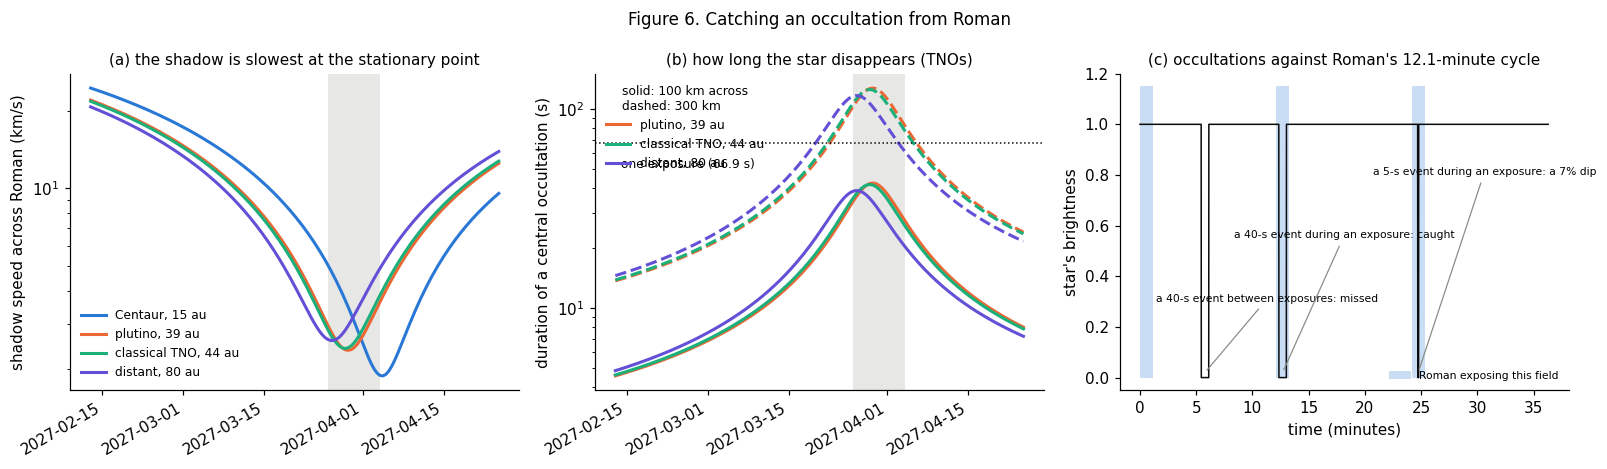

plutino, 39 au        : shadow 2.4 to 22.0 km/s; a 100-km TNO occults for 5 to 42 s, a 300-km one for 14 to 127 s; chance of overlapping an exposure 10%-15% (100 km), 11%-27% (300 km)
classical TNO, 44 au  : shadow 2.4 to 21.7 km/s; a 100-km TNO occults for 5 to 42 s, a 300-km one for 14 to 125 s; chance of overlapping an exposure 10%-15% (100 km), 11%-26% (300 km)
distant, 80 au        : shadow 2.6 to 20.7 km/s; a 100-km TNO occults for 5 to 39 s, a 300-km one for 15 to 116 s; chance of overlapping an exposure 10%-15% (100 km), 11%-25% (300 km)


In [7]:
season_t = Time(roman.SPRING_2027[0], scale="utc").tdb.jd + np.arange(0, 71, 0.5) - JD
season_d = Time(season_t + JD, format="jd", scale="tdb").datetime
fig, axs = plt.subplots(1, 3, figsize=(15, 4.3))
speeds = {}
for (name, x), c in zip(truth.items(), roman.COLOURS):
    v = roman.shadow_speed_km_s(x, T_MID, season_t, TRAJ, "Roman")
    speeds[name] = v
    axs[0].plot(season_d, v, color=c, lw=2, label=name)
for D, ls in ((100, "-"), (300, "--")):
    for (name, v), c in zip(speeds.items(), roman.COLOURS):
        if name.startswith("Centaur"):
            continue
        axs[1].plot(season_d, D / v, ls, color=c, lw=2, label=name if D == 100 else None)
axs[1].axhline(roman.EXPOSURE_S, color=roman.INK, lw=1, ls=":")
axs[1].text(season_d[2], roman.EXPOSURE_S * 0.85, "one exposure (66.9 s)", fontsize=8, va="top")
for ax in axs[:2]:
    ax.axvspan(*STATIONARY, color=roman.MUTED, alpha=0.2, lw=0)
    ax.set_yscale("log")
    for lab in ax.get_xticklabels():
        lab.set_rotation(30); lab.set_ha("right")
axs[0].set_ylabel("shadow speed across Roman (km/s)")
axs[1].set_ylabel("duration of a central occultation (s)")
axs[0].legend(fontsize=8, frameon=False)
axs[1].legend(fontsize=8, frameon=False, loc="upper left", title="solid: 100 km across\ndashed: 300 km", title_fontsize=8)
axs[0].set_title("(a) the shadow is slowest at the stationary point", fontsize=10)
axs[1].set_title("(b) how long the star disappears (TNOs)", fontsize=10)

ax = axs[2]
tline = np.linspace(0, 3 * roman.CADENCE_S, 6000)
exposing = (tline % roman.CADENCE_S) < roman.EXPOSURE_S
ax.fill_between(tline / 60, 0, 1.15, where=exposing, color=roman.ROMAN_C, alpha=0.25, lw=0, label="Roman exposing this field")
events = [(0.45 * roman.CADENCE_S, 40, "a 40-s event between exposures: missed", 0.30),
          (roman.CADENCE_S + 15, 40, "a 40-s event during an exposure: caught", 0.55),
          (2 * roman.CADENCE_S + 30, 5, "a 5-s event during an exposure: a 7% dip", 0.80)]
flux = np.ones_like(tline)
for t0, dur, lab, y in events:
    flux[(tline >= t0) & (tline < t0 + dur)] = 0.0
    ax.annotate(lab, ((t0 + dur / 2) / 60, 0.02), xytext=(t0 / 60 - 4, y), fontsize=7,
                arrowprops=dict(arrowstyle="-", color=roman.MUTED, lw=0.8))
ax.plot(tline / 60, flux, color=roman.INK, lw=1)
ax.set_ylim(-0.05, 1.2)
ax.set_xlabel("time (minutes)")
ax.set_ylabel("star's brightness")
ax.legend(fontsize=7, frameon=False, loc="lower right")
ax.set_title("(c) occultations against Roman's 12.1-minute cycle", fontsize=10)
fig.suptitle("Figure 6. Catching an occultation from Roman", fontsize=11)
plt.tight_layout()
plt.show()

for name, v in speeds.items():
    if name.startswith("Centaur"):
        continue
    d100, d300 = 100 / v, 300 / v
    print(f"{name:22s}: shadow {v.min():.1f} to {v.max():.1f} km/s; a 100-km TNO occults for {d100.min():.0f} to {d100.max():.0f} s, "
          f"a 300-km one for {d300.min():.0f} to {d300.max():.0f} s; chance of overlapping an exposure "
          f"{roman.capture_probability(d100).min():.0%}-{roman.capture_probability(d100).max():.0%} (100 km), "
          f"{roman.capture_probability(d300).min():.0%}-{roman.capture_probability(d300).max():.0%} (300 km)")

The shadow moves at about 2 to 22 km/s, slowest at the stationary point, so a 100-km TNO hides a star for 5 to 40 s and a 300-km one for up to about two minutes. For an event at a random moment the chance that it overlaps one of the field's exposures is roughly one in ten, more for the larger, longer events (printed above); and an event shorter than an exposure dims the star only by the fraction of the exposure it lasts. (Each exposure is read several times as it accumulates, which gives some time resolution within it.) Events near the stationary point are the best: the longest, so the most likely to be caught and the deepest.

Now the width. Figure 7 shows the probability that the star is occulted as seen by the observer, as a function of how far the *predicted* centre line of the shadow passes from it, for the plutino-like object with the cross-track uncertainties at the end of a 14- and a 28-day arc. When the uncertainty is small compared with the object, the prediction is sharp: a star within the object's radius of the predicted line is almost certainly occulted, one well outside it almost certainly not. When it is comparable with the object or larger, the prediction blurs into a modest probability spread over a wider band.

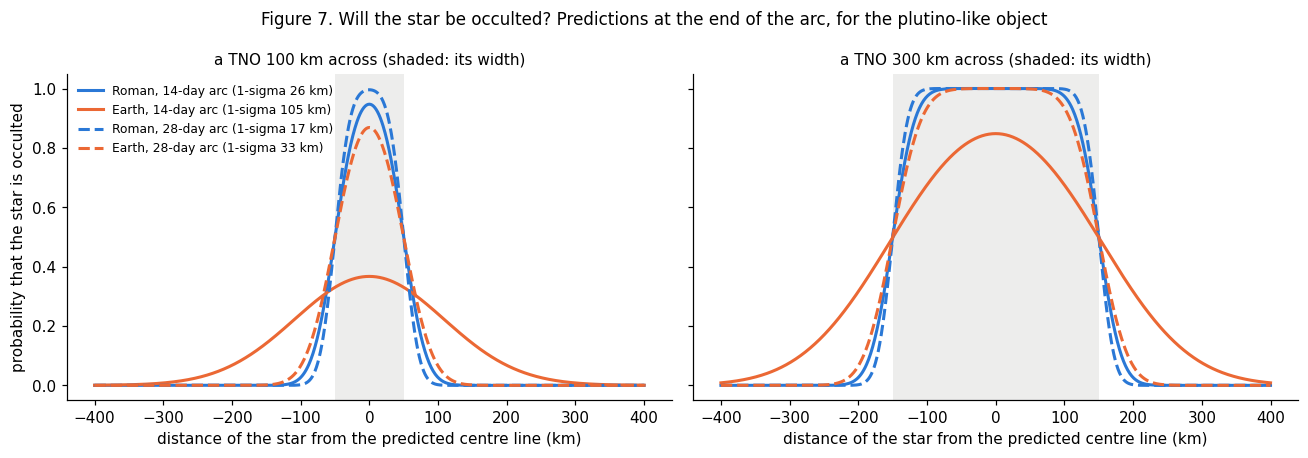

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
off = np.linspace(-400, 400, 801)
for ax, R in zip(axs, (50, 150)):
    for arc, ls in ((14, "-"), (28, "--")):
        sp = rows[("plutino, 39 au", arc)][0]
        for who, c in (("Roman", roman.ROMAN_C), ("Earth", roman.EARTH_C)):
            sig = sp[who]["across"]
            ax.plot(off, roman.occultation_probability(off, R, sig), ls, color=c, lw=2,
                    label=f"{who}, {arc}-day arc (1-sigma {sig:.0f} km)")
    ax.axvspan(-R, R, color=roman.MUTED, alpha=0.15, lw=0)
    ax.set_xlabel("distance of the star from the predicted centre line (km)")
    ax.set_title(f"a TNO {2 * R} km across (shaded: its width)", fontsize=10)
axs[0].set_ylabel("probability that the star is occulted")
axs[0].legend(fontsize=8, frameon=False, loc="upper left")
fig.suptitle("Figure 7. Will the star be occulted? Predictions at the end of the arc, for the plutino-like object", fontsize=11)
plt.tight_layout()
plt.show()

### 5.2 Seen from the ground: a different track

From the ground the problem changes in two ways. The first is Section 4's: the path is less certain, because the Earth sees part of the long axis of the uncertainty cloud. The second is more basic. The same parallax shifts the object's whole track on the sky: from about 1.6 million km away, a TNO at 39 au appears displaced by roughly a minute of arc. So a star that Roman sees occulted is generally *not* occulted as seen from the Earth, or not at the same time; ground-based predictions concern the stars along the Earth's own track. Figure 8 shows both tracks, a week after the end of a 14-day arc.

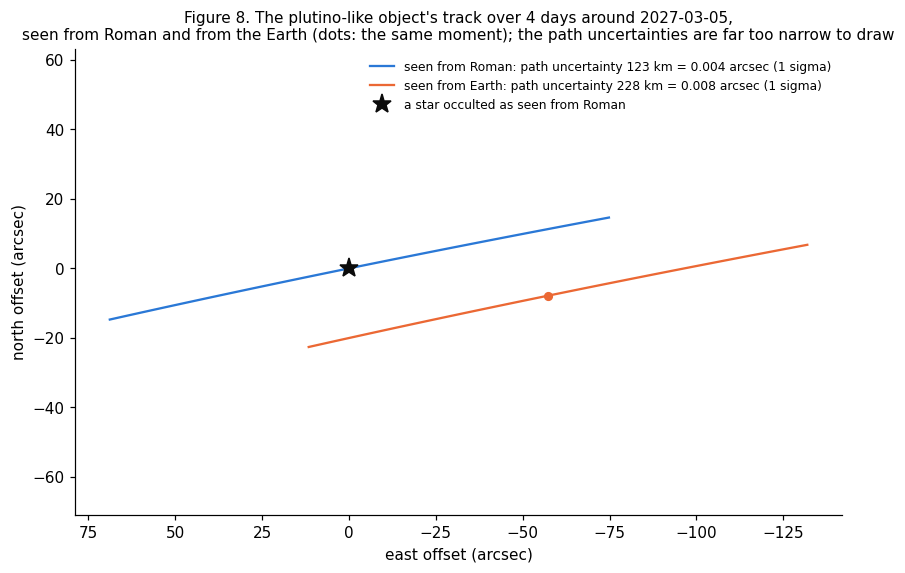

at the same moment the object appears 58 arcsec apart as seen from Roman and from the Earth


In [9]:
O, f, S = fits[("plutino, 39 au", 14)]
t_c = O.t[-1] + 7
tt = t_c + np.linspace(-2, 2, 81)
ref = roman.sky_track(f.state, f.t, np.array([t_c]), TRAJ, "Roman")
ss = roman.spread_series(S, f.t, f.state, tt, TRAJ)
fig, ax = plt.subplots(figsize=(9, 5.5))
for who, c in (("Roman", roman.ROMAN_C), ("Earth", roman.EARTH_C)):
    e, n = roman.sky_track(f.state, f.t, tt, TRAJ, who, ref=(ref[0][0], ref[1][0]))
    dist_km = np.linalg.norm(ephem.propagate(f.state[None], f.t, tt)[:, 0, :3] - roman.observer(TRAJ, tt, who), axis=1) * KM
    sig_km = np.median(ss[who]["across"])
    sig_as = sig_km / np.median(dist_km) / frames.ARCSEC
    ax.plot(e, n, color=c, lw=1.5, label=f"seen from {who}: path uncertainty {sig_km:.0f} km = {sig_as:.3f} arcsec (1 sigma)")
    ax.plot(e[40], n[40], "o", color=c, ms=5)
ax.plot(0, 0, marker="*", color=roman.INK, ms=13, ls="none", label="a star occulted as seen from Roman")
ax.invert_xaxis()
ax.set_aspect("equal", adjustable="datalim")
ax.set_xlabel("east offset (arcsec)")
ax.set_ylabel("north offset (arcsec)")
ax.legend(fontsize=8, frameon=False, loc="best")
ax.set_title(f"Figure 8. The plutino-like object's track over 4 days around {Time(t_c + JD, format='jd', scale='tdb').utc.iso[:10]},\n"
             "seen from Roman and from the Earth (dots: the same moment); the path uncertainties are far too narrow to draw", fontsize=10)
plt.show()
e, n = roman.sky_track(f.state, f.t, np.array([t_c]), TRAJ, "Earth", ref=(ref[0][0], ref[1][0]))
print(f"at the same moment the object appears {np.hypot(e[0], n[0]):.0f} arcsec apart as seen from Roman and from the Earth")

The two tracks are about a minute of arc apart, while the path uncertainties, a few hundred km, are a few thousandths of an arcsecond: ten thousand times smaller. So the two observers see the object pass in front of different stars. A ground-based prediction therefore needs its own search of the star catalogue along the Earth's track; it inherits the wider path uncertainty of Section 4, and, since observers must travel to the path and record for long enough, the timing uncertainty too. Together these make a ground-based occultation by a Roman TNO a harder prediction than one seen by Roman itself, which needs only the narrow path, but must then be lucky with its exposure cycle.

## 6. Summary

* From part of a 70-day stare, Roman's milliarcsecond astrometry determines a TNO's semi-major axis to $\sigma_a/a \sim 10^{-3}$ in two to four weeks (for objects of about F146 = 24), and the full season to $\sim 10^{-5}$. Nearer objects need shorter arcs.
* The resulting uncertainty is a long, thin cloud along Roman's line of sight. Roman sees it end on; observers on the Earth, 1.5 million km away and largely across the line of sight, see part of its length: an extra spread of about $B_\perp\,\sigma_\rho/\rho$, a few hundred km after two weeks, independent of the object's distance.
* For occultation predictions, the path stays within a few hundred km for two months after a 28-day arc but degrades within a week or two after a 14-day one; timing uncertainties grow from seconds to minutes; and the five-month gap between seasons is the main obstacle for any arc short of the full season. Near the stationary points, which fall in the spring season because the bulge is observed near quadrature, the long axis of the uncertainty turns across the motion and the path uncertainty peaks.
* For an occultation seen by Roman itself, only the path decides whether it happens, and Roman's narrow path uncertainty makes that prediction sharp; but the shadow passes in seconds to minutes, so Roman's fixed 12.1-minute cycle catches only about one event in ten, best near the stationary point where the shadow is slowest. From the ground the object follows a different track, about a minute of arc away, with a wider path uncertainty and a timing window to cover: a harder prediction.

## 7. Going further

* **Brightness.** Change `MAG`: each magnitude changes the precision by a factor of 2.5, and the arc needed for a given $\sigma_a/a$ accordingly.
* **Combining Roman with the ground.** A single ground-based position taken during the season adds a baseline of 1.5 million km to Roman's data and directly measures the distance (Giovinazzi, Blake & Bernardinelli 2021); add one with `orbunc.simulate.astrometry` and refit.
* **Real orbits.** Replace the synthetic objects by known TNOs whose paths cross the fields (Porter et al. 2022 used a far longer baseline, from New Horizons, for the same purpose).

## References

* Bernstein, G. & Khushalani, B. (2000), *Orbit fitting and uncertainties for Kuiper Belt objects*, AJ 120, 3323. [ADS](https://ui.adsabs.harvard.edu/abs/2000AJ....120.3323B/abstract)
* Giovinazzi, M. R., Blake, C. H. & Bernardinelli, P. H. (2021), *Enhancing ground-based observations of trans-Neptunian objects using a single-epoch parallax measurement from L2*, PASP 133, 114401. [ADS](https://ui.adsabs.harvard.edu/abs/2021PASP..133k4401G/abstract)
* Gould, A. (2014), *WFIRST ultra-precise astrometry I: Kuiper Belt objects*, JKAS 47, 279. [ADS](https://ui.adsabs.harvard.edu/abs/2014JKAS...47..279G/abstract)
* Holler, B. J., Milam, S. N., Bauer, J. M., et al. (2018), *Solar system science with the Wide-Field Infrared Survey Telescope*, JATIS 4, 034003. [ADS](https://ui.adsabs.harvard.edu/abs/2018JATIS...4c4003H/abstract)
* McKinnon, K. A. & van der Marel, R. P. (2026), *Simulating Roman+Gaia combined astrometry, parallaxes, and proper motions*, PASP 138, 044507. [ADS](https://ui.adsabs.harvard.edu/abs/2026PASP..138d4507M/abstract)
* Porter, S. B., Spencer, J. R., Verbiscer, A., et al. (2022), *Orbits and occultation opportunities of 15 TNOs observed by New Horizons*, PSJ 3, 23. [ADS](https://ui.adsabs.harvard.edu/abs/2022PSJ.....3...23P/abstract)
* Roman Observations Time Allocation Committee (2025), *Final report and recommendations*, arXiv:2505.10574. [ADS](https://ui.adsabs.harvard.edu/abs/2025arXiv250510574O/abstract)
* WFIRST Astrometry Working Group, Sanderson, R. E., Bellini, A., et al. (2019), *Astrometry with the Wide-Field Infrared Space Telescope*, JATIS 5, 044005. [ADS](https://ui.adsabs.harvard.edu/abs/2019JATIS...5d4005W/abstract)
* STScI Roman documentation (RDox), Galactic Bulge Time Domain Survey and the provisional schedule: https://roman-docs.stsci.edu/
* JPL Horizons: https://ssd.jpl.nasa.gov/horizons/